# Final held-out evaluation

Frozen models screen hourly at N=3 (primary) and N=5 (secondary). The fixed test spans 8 January to 3 February 2026, 08:00 UTC. Opportunity prediction and economic replay are evaluated separately. The final period is opened for this evaluation; no models are refitted or tuned on its outcomes.

Read [the final findings](../docs/reports/final_evaluation.md) and [the previously frozen protocol](../docs/reports/final_test_protocol.md). Default execution verifies and displays saved results.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import pandas as pd
import torch
from threadpoolctl import threadpool_limits
from IPython.display import display, Image
from src.paths import PROCESSED_DIR
from src.data.final_evaluation import build
from src.models.final_evaluation import evaluate
from src.simulator.final_evaluation import replay
from src.reporting.final_evaluation import build_report, verify_analysis, LABELS

DATA = PROCESSED_DIR / 'final_evaluation'
MODELS = ROOT / 'results/final_evaluation'
REPLAY = ROOT / 'results/final_replay'
RUN_FINAL = False
REBUILD_REPORT = False
# Rebuilding requires fresh DATA, MODELS and REPLAY paths. It never refits models.
torch.set_num_threads(4)
with threadpool_limits(limits=4):
    if RUN_FINAL:
        build(DATA, open_final=True)
        evaluate(MODELS, DATA)
        replay(REPLAY, DATA, MODELS)
    if REBUILD_REPORT:
        build_report(DATA, MODELS, REPLAY)
    manifest = verify_analysis(DATA, MODELS, REPLAY)
print('Verified final data, predictions, replay and report.')
print('Final outcomes opened:', manifest['final_outcomes_opened'])
print('Models retrained:', manifest['models_retrained'])

Verified final data, predictions, replay and report.
Final outcomes opened: True
Models retrained: False


## Evaluated evidence

All eligible events are ranked before consulting future label coverage. Unknown outcomes consume slots and do not become negative or zero-valued examples. First/last timestamp coverage is not the same as a valid label: observed blocking legs can make an otherwise incomplete basket decidable, while invalid books can make an apparently complete window unknown. No audited ladder relationship reaches this test period.

In [2]:
display(pd.Series(json.loads((DATA / 'summary.json').read_text()), name='Final dataset'))
display(pd.read_csv(REPLAY / 'analysis/event_label_counts.csv'))
print('Quoted-value totals sum peak basket margins as ranking weights, not tradable hourly profits.')

rows                         2473
events                          8
known                        1625
positive                       16
negative                     1609
unknown                       848
witnessed_in_unknown            0
peak_quote_value         84.61953
final_outcomes_opened        True
Name: Final dataset, dtype: object

,event_slug,rows,known,positives,peak_quote_value,witnessed_in_unknown,unknown
0,2026-mens-australian-open-winner,235,27,0,0.00000,0,208
1,elon-musk-of-tweets-january-2-january-9,45,18,0,0.00000,0,27
2,elon-musk-of-tweets-january-6-january-13,141,106,0,0.00000,0,35
3,elon-musk-of-tweets-january-9-january-16,213,199,0,0.00000,0,14
4,fed-decision-in-january,503,377,13,84.29967,0,126
5,next-country-us-strikes-918,246,164,3,0.31986,0,82
6,us-next-strikes-iran-on,517,269,0,0.00000,0,248
7,which-company-has-the-best-ai-model-end-of-jan...,573,465,0,0.00000,0,108


Quoted-value totals sum peak basket margins as ranking weights, not tradable hourly profits.


## Layer 1: opportunity prediction

TabM is the predeclared value-model candidate; fixed logistic is the occurrence reference. The primary comparison is peak quoted-value capture@3 versus quoted-gap. All saved policies remain displayed. The two forest names refer to the same final fitted model. Competitive-hour results are secondary; full-period results remain primary. At N=5 every policy monitors the same eligible pool.

Every saved model and quoted-gap captures all 16 known positive hours at N=3 and all $84.62 of the peak-value weighting target. The held-out sample shows no capture advantage for ML at this budget; positives occur in only two events.

In [3]:
metrics = pd.read_csv(MODELS / 'metrics.csv')
columns = ['scope','subset','model','top_n','positive_windows','captured_positive_windows','recall',
           'total_peak_value','captured_peak_value','peak_value_recall','selected_unknown_fraction',
           'expected_random_recall','expected_random_value_recall']
models = list(LABELS)
headline = metrics.loc[metrics.scope.isin(['frozen_supported_universe','development_events_only']) & metrics.model.isin(models)]
display(headline[columns].sort_values(['scope','top_n','subset','model']).round(4))
display(pd.read_csv(REPLAY / 'analysis/paired_capture_intervals.csv').query('top_n == 3').round(4))

,scope,subset,model,top_n,positive_windows,captured_positive_windows,recall,total_peak_value,captured_peak_value,peak_value_recall,selected_unknown_fraction,expected_random_recall,expected_random_value_recall
109,development_events_only,competitive,fixed_book_logistic,3,6,6,1.0,38.9332,38.9332,1.0,0.1324,0.7500,0.7500
111,development_events_only,competitive,fixed_book_random_forest,3,6,6,1.0,38.9332,38.9332,1.0,0.1348,0.7500,0.7500
113,development_events_only,competitive,monitor_all,3,6,6,1.0,38.9332,38.9332,1.0,0.1018,0.7500,0.7500
115,development_events_only,competitive,n3_book_logistic,3,6,6,1.0,38.9332,38.9332,1.0,0.0047,0.7500,0.7500
117,development_events_only,competitive,n3_book_random_forest,3,6,6,1.0,38.9332,38.9332,1.0,0.1348,0.7500,0.7500
119,development_events_only,competitive,n3_tabm_two_stage,3,6,6,1.0,38.9332,38.9332,1.0,0.0378,0.7500,0.7500
121,development_events_only,competitive,quoted_gap_rule,3,6,6,1.0,38.9332,38.9332,1.0,0.1466,0.7500,0.7500
108,development_events_only,full,fixed_book_logistic,3,13,13,1.0,84.2997,84.2997,1.0,0.2358,0.8846,0.8845
110,development_events_only,full,fixed_book_random_forest,3,13,13,1.0,84.2997,84.2997,1.0,0.2366,0.8846,0.8845
112,development_events_only,full,monitor_all,3,13,13,1.0,84.2997,84.2997,1.0,0.2102,0.8846,0.8845


,scope,top_n,model,metric,families,difference,lower95,upper95
0,development_events_only,3,quoted_gap_rule,recall,3,0.0,0.0,0.0
1,development_events_only,3,quoted_gap_rule,value,3,0.0,0.0,0.0
2,development_events_only,3,fixed_book_logistic,recall,3,0.0,0.0,0.0
3,development_events_only,3,fixed_book_logistic,value,3,0.0,0.0,0.0
4,development_events_only,3,n3_book_logistic,recall,3,0.0,0.0,0.0
5,development_events_only,3,n3_book_logistic,value,3,0.0,0.0,0.0
6,development_events_only,3,fixed_book_random_forest,recall,3,0.0,0.0,0.0
7,development_events_only,3,fixed_book_random_forest,value,3,0.0,0.0,0.0
8,development_events_only,3,n3_book_random_forest,recall,3,0.0,0.0,0.0
9,development_events_only,3,n3_book_random_forest,value,3,0.0,0.0,0.0


## Layer 2: economic evaluation

The primary scenario is 100 ms arrival and uncapped capital/shares. Partial baskets unwind after one second; there is no imposed random failure probability. Frozen zero cohort exchange fees and zero extra attempt costs remain scenario assumptions. Entries respect the fixed endpoint; later recorded context can resolve existing exits only. Unknown execution outcomes are disclosed separately from known P&L.

All saved models and quoted-gap return $32.31 at 100 ms: $37.93 completed margin minus $5.62 partial losses, with zero unknown attempted executions. The same selections return ?$12.81 at 500 ms. Final outcomes are evaluated; no additional tuning uses them.

,scope,top_n,model,attempts,completed,partial_attempts,unknown_attempts,known_pnl_usd,partial_pnl_usd,max_drawdown_usd,no_settlement_funding_usd
2,development_events_only,3,fixed_book_logistic,17,16,1,0,36.55,-1.28,1.28,22524.45
7,development_events_only,3,fixed_book_random_forest,17,16,1,0,36.55,-1.28,1.28,22524.45
12,development_events_only,3,monitor_all,17,16,1,0,36.55,-1.28,1.28,22524.45
17,development_events_only,3,n3_book_logistic,17,16,1,0,36.55,-1.28,1.28,22524.45
22,development_events_only,3,n3_book_random_forest,17,16,1,0,36.55,-1.28,1.28,22524.45
27,development_events_only,3,n3_tabm_two_stage,17,16,1,0,36.55,-1.28,1.28,22524.45
32,development_events_only,3,quoted_gap_rule,17,16,1,0,36.55,-1.28,1.28,22524.45
137,development_events_only,5,fixed_book_logistic,17,16,1,0,36.55,-1.28,1.28,22524.45
142,development_events_only,5,fixed_book_random_forest,17,16,1,0,36.55,-1.28,1.28,22524.45
147,development_events_only,5,monitor_all,17,16,1,0,36.55,-1.28,1.28,22524.45


,scope,top_n,arrival_delay_s,mean,min,max,std
2,development_events_only,3,0.1,33.52,31.52,37.82,2.20
7,development_events_only,5,0.1,36.55,36.55,36.55,0.00
12,frozen_supported_universe,3,0.1,23.23,5.41,34.70,9.17
17,frozen_supported_universe,5,0.1,32.31,32.31,32.31,0.00
20,leave_out:2026-mens-australian-open-winner,3,0.1,23.23,5.41,34.70,9.17
21,leave_out:elon-musk-of-tweets-january-2-january-9,3,0.1,23.23,5.41,34.70,9.17
22,leave_out:elon-musk-of-tweets-january-6-januar...,3,0.1,26.05,8.63,39.72,9.90
23,leave_out:elon-musk-of-tweets-january-9-januar...,3,0.1,26.54,8.63,40.91,10.03
24,leave_out:fed-decision-in-january,3,0.1,-4.24,-4.24,-4.24,0.00
25,leave_out:next-country-us-strikes-918,3,0.1,32.24,27.11,37.62,2.31


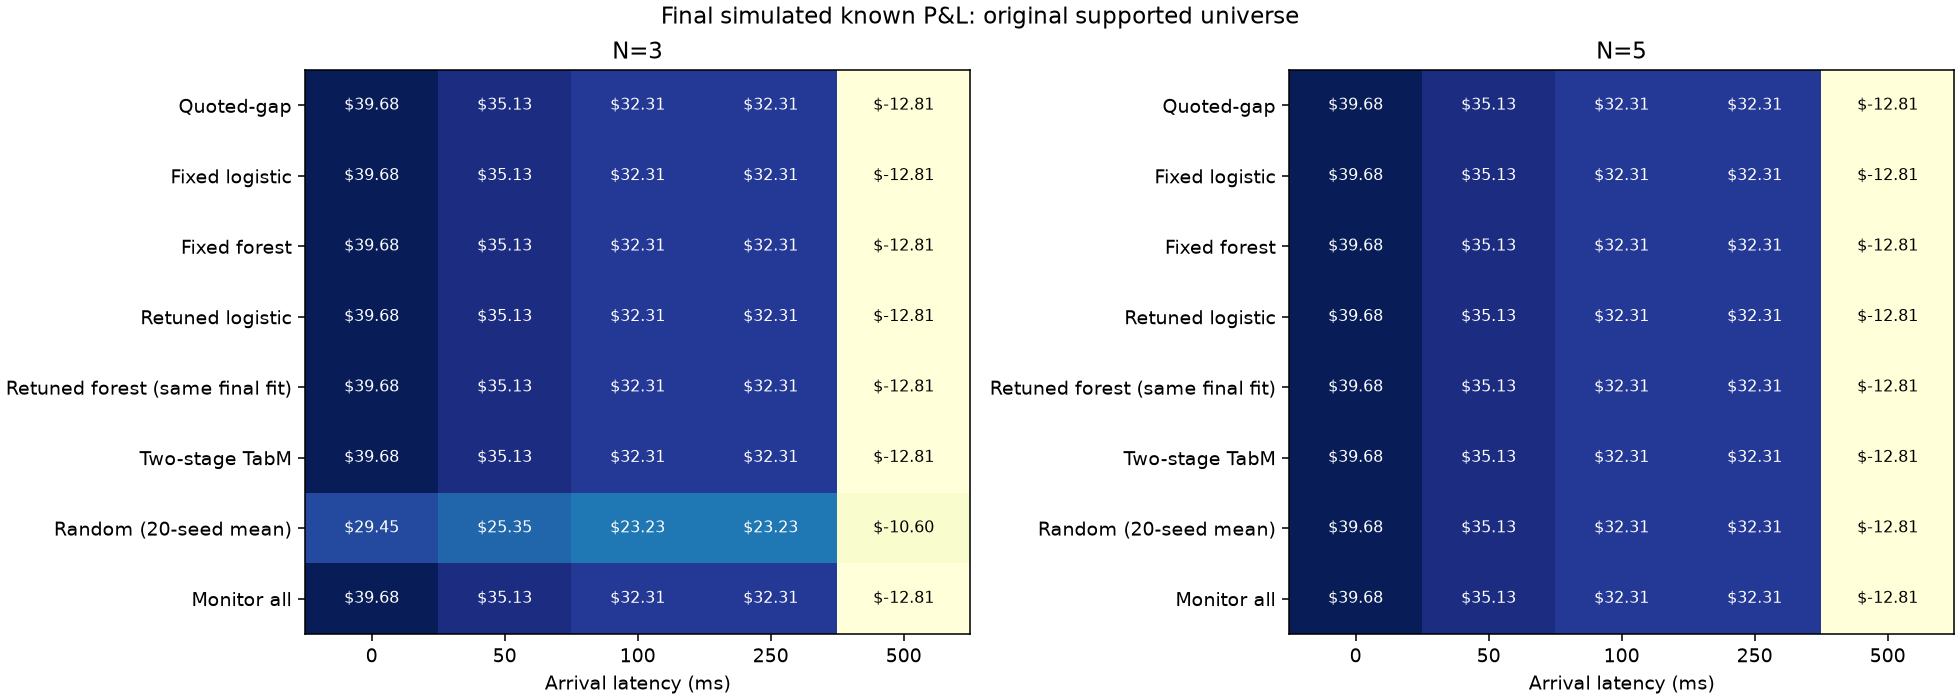

,scope,arrival_delay_s,n5_economic_equality
0,development_events_only,0.00,True
1,development_events_only,0.05,True
2,development_events_only,0.10,True
3,development_events_only,0.25,True
4,development_events_only,0.50,True
5,frozen_supported_universe,0.00,True
6,frozen_supported_universe,0.05,True
7,frozen_supported_universe,0.10,True
8,frozen_supported_universe,0.25,True
9,frozen_supported_universe,0.50,True


In [4]:
economic = pd.read_csv(REPLAY / 'summary.csv')
primary = economic.loc[economic.scope.isin(['frozen_supported_universe','development_events_only']) & economic.arrival_delay_s.eq(.1)]
columns = ['scope','top_n','model','attempts','completed','partial_attempts','unknown_attempts','known_pnl_usd',
           'partial_pnl_usd','max_drawdown_usd','no_settlement_funding_usd']
display(primary.loc[primary.model.isin(models), columns].round(2))
display(pd.read_csv(REPLAY / 'analysis/random_replay_distribution.csv').query('arrival_delay_s == 0.1').round(2))
display(Image(filename=str(REPLAY / 'analysis/frozen_supported_universe_latency.png')))
display(pd.read_csv(REPLAY / 'consistency.csv'))

## Concentration, uncertainty and P&L paths

Separate axes compare each policy with quoted-gap. Event contributions, symmetric leave-one-event-out reranking and paired family intervals describe concentration. A small number of positive hours, unknown outcomes, few event families and retrospective membership limit generalisation. These are conditional displayed-depth simulations, not observed live fills.

January Fed contributes +$36.55 and the other traded event ?$4.24. Gray quoted-gap curves and blue policy curves coincide in the primary final comparison. Flat paths through the end of the fixed period are retained. Apparent equality on this small, incompletely recorded cohort does not establish general model equivalence.

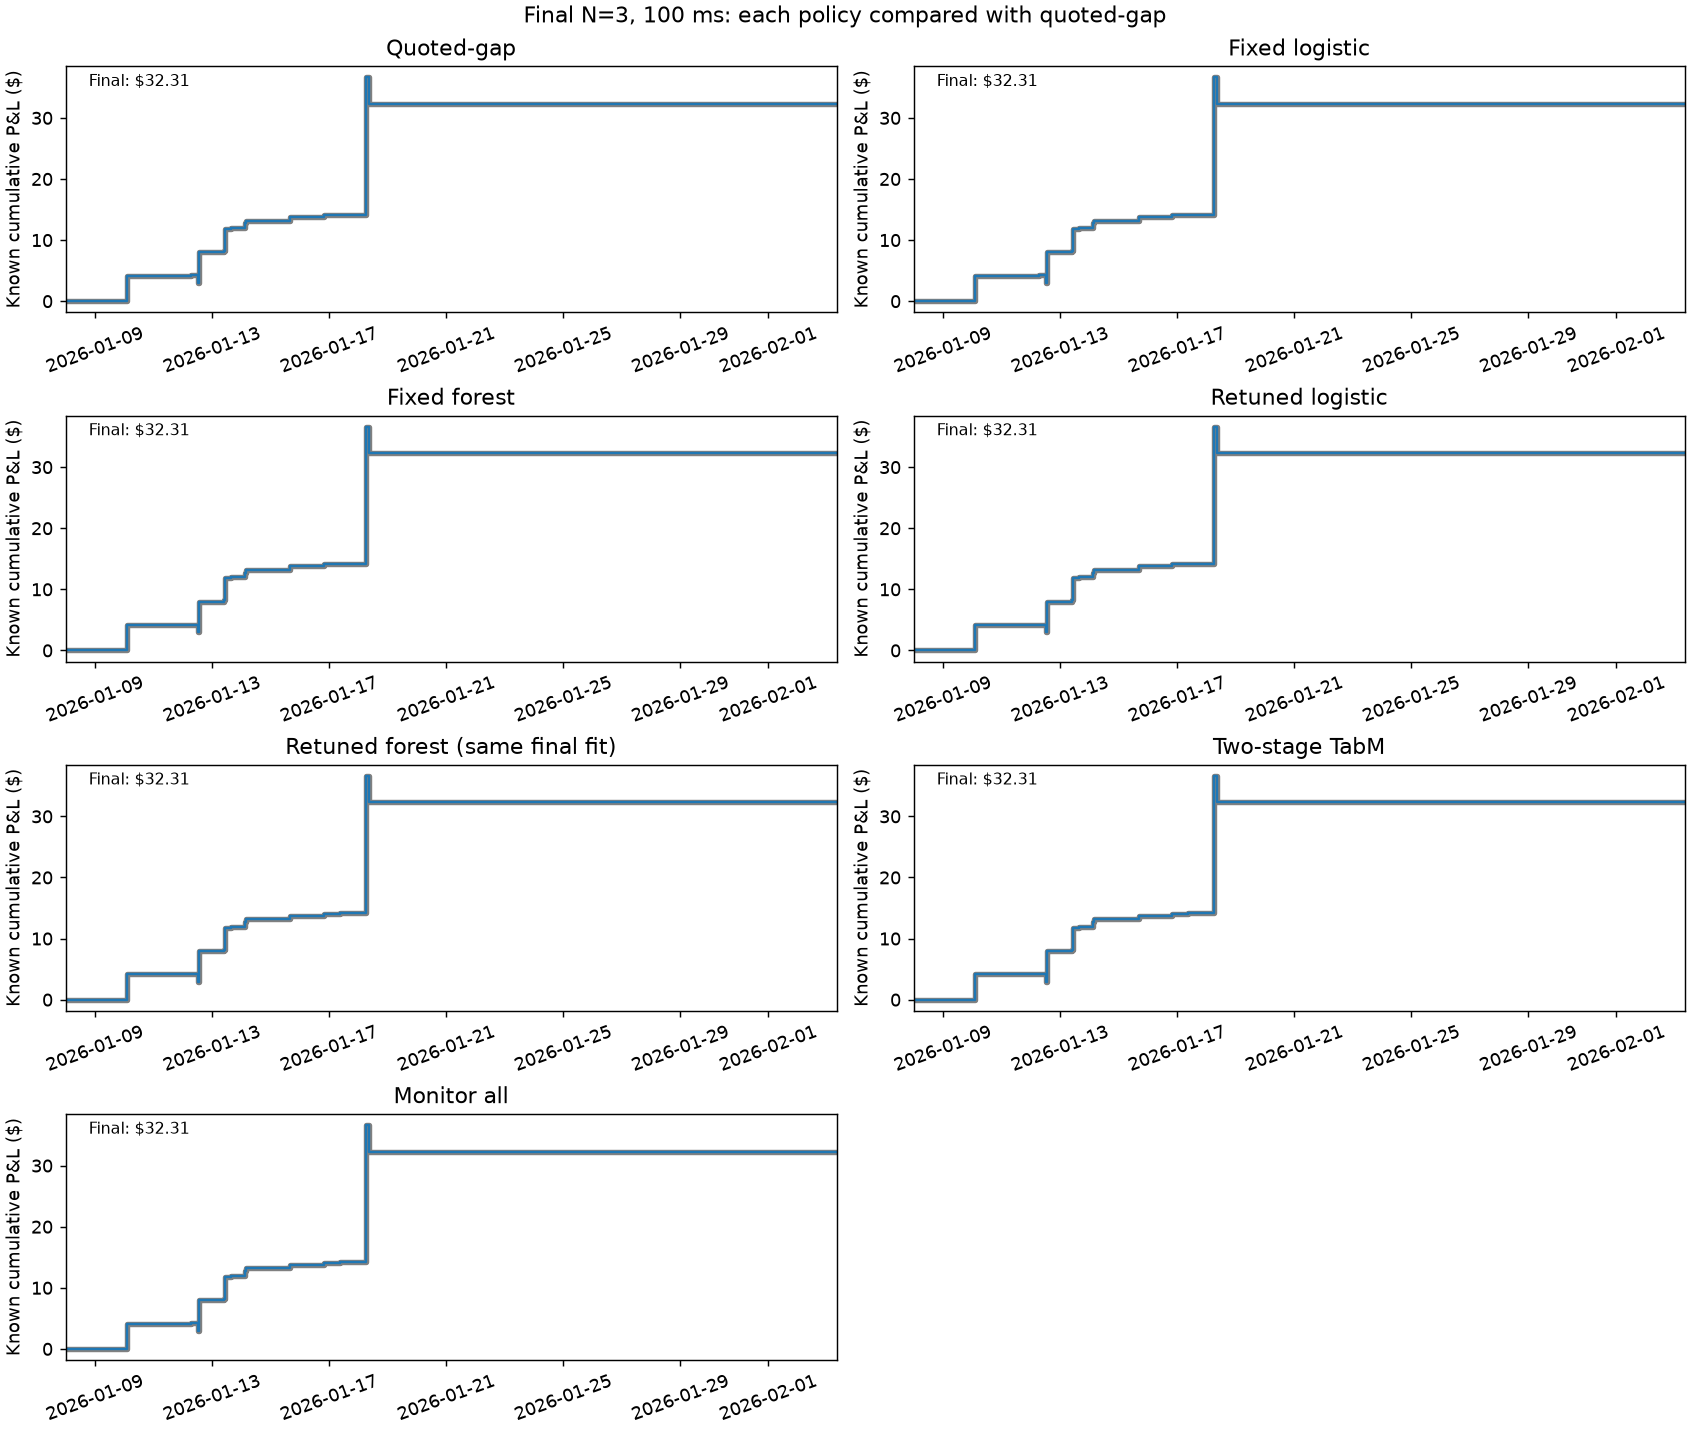

,scope,top_n,arrival_delay_s,model,event_slug,pnl_usd
378,frozen_supported_universe,3,0.1,fixed_book_logistic,fed-decision-in-january,36.55
379,frozen_supported_universe,3,0.1,fixed_book_logistic,next-country-us-strikes-918,-4.24
380,frozen_supported_universe,3,0.1,fixed_book_random_forest,fed-decision-in-january,36.55
381,frozen_supported_universe,3,0.1,fixed_book_random_forest,next-country-us-strikes-918,-4.24
382,frozen_supported_universe,3,0.1,monitor_all,fed-decision-in-january,36.55
383,frozen_supported_universe,3,0.1,monitor_all,next-country-us-strikes-918,-4.24
384,frozen_supported_universe,3,0.1,n3_book_logistic,fed-decision-in-january,36.55
385,frozen_supported_universe,3,0.1,n3_book_logistic,next-country-us-strikes-918,-4.24
386,frozen_supported_universe,3,0.1,n3_book_random_forest,fed-decision-in-january,36.55
387,frozen_supported_universe,3,0.1,n3_book_random_forest,next-country-us-strikes-918,-4.24


,scope,top_n,model,families,difference_usd,lower95,upper95
0,frozen_supported_universe,3,quoted_gap_rule,5,0.0,0.0,0.0
1,frozen_supported_universe,3,fixed_book_logistic,5,0.0,0.0,0.0
2,frozen_supported_universe,3,n3_book_logistic,5,0.0,0.0,0.0
3,frozen_supported_universe,3,fixed_book_random_forest,5,0.0,0.0,0.0
4,frozen_supported_universe,3,n3_book_random_forest,5,0.0,0.0,0.0
5,frozen_supported_universe,3,n3_tabm_two_stage,5,0.0,0.0,0.0
12,development_events_only,3,quoted_gap_rule,3,0.0,0.0,0.0
13,development_events_only,3,fixed_book_logistic,3,0.0,0.0,0.0
14,development_events_only,3,n3_book_logistic,3,0.0,0.0,0.0
15,development_events_only,3,fixed_book_random_forest,3,0.0,0.0,0.0


,scope,model,known_pnl_usd,unknown_attempts
0,leave_out:2026-mens-australian-open-winner,fixed_book_logistic,32.31,0
1,leave_out:2026-mens-australian-open-winner,fixed_book_random_forest,32.31,0
2,leave_out:2026-mens-australian-open-winner,monitor_all,32.31,0
3,leave_out:2026-mens-australian-open-winner,n3_book_logistic,32.31,0
4,leave_out:2026-mens-australian-open-winner,n3_book_random_forest,32.31,0
5,leave_out:2026-mens-australian-open-winner,n3_tabm_two_stage,32.31,0
6,leave_out:2026-mens-australian-open-winner,quoted_gap_rule,32.31,0
27,leave_out:elon-musk-of-tweets-january-2-january-9,fixed_book_logistic,32.31,0
28,leave_out:elon-musk-of-tweets-january-2-january-9,fixed_book_random_forest,32.31,0
29,leave_out:elon-musk-of-tweets-january-2-january-9,monitor_all,32.31,0


,model,rows,maximum_error
0,fixed_book_logistic,2473,0.000000e+00
1,fixed_book_random_forest,2473,2.220446e-16
2,n3_book_logistic,2473,0.000000e+00
3,n3_book_random_forest,2473,2.220446e-16
4,n3_tabm_two_stage,2473,0.000000e+00
5,quoted_gap_rule,2473,0.000000e+00


In [5]:
display(Image(filename=str(REPLAY / 'analysis/primary_pnl_small_multiples.png')))
contributions = pd.read_csv(REPLAY / 'analysis/event_pnl.csv')
display(contributions.loc[contributions.scope.eq('frozen_supported_universe') & contributions.top_n.eq(3) & contributions.arrival_delay_s.eq(.1) & contributions.model.isin(models)].round(2))
display(pd.read_csv(REPLAY / 'analysis/paired_pnl_intervals.csv').query('top_n == 3').round(2))
leave_out = pd.read_csv(REPLAY / 'analysis/leave_event_out_economics.csv')
display(leave_out.loc[leave_out.model.isin(models), ['scope','model','known_pnl_usd','unknown_attempts']].round(2))
display(pd.read_csv(REPLAY / 'analysis/prediction_verification.csv'))